In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
df = pd.read_csv("exoplanet_data.csv", comment = "#")

In [4]:
df.shape

(599, 92)

In [5]:
# there are 599 rows and 92 columns

In [6]:
df.columns

Index(['pl_name', 'hostname', 'default_flag', 'sy_snum', 'sy_pnum',
       'discoverymethod', 'disc_year', 'disc_facility', 'soltype',
       'pl_controv_flag', 'pl_refname', 'pl_orbper', 'pl_orbpererr1',
       'pl_orbpererr2', 'pl_orbperlim', 'pl_orbsmax', 'pl_orbsmaxerr1',
       'pl_orbsmaxerr2', 'pl_orbsmaxlim', 'pl_rade', 'pl_radeerr1',
       'pl_radeerr2', 'pl_radelim', 'pl_radj', 'pl_radjerr1', 'pl_radjerr2',
       'pl_radjlim', 'pl_bmasse', 'pl_bmasseerr1', 'pl_bmasseerr2',
       'pl_bmasselim', 'pl_bmassj', 'pl_bmassjerr1', 'pl_bmassjerr2',
       'pl_bmassjlim', 'pl_bmassprov', 'pl_orbeccen', 'pl_orbeccenerr1',
       'pl_orbeccenerr2', 'pl_orbeccenlim', 'pl_insol', 'pl_insolerr1',
       'pl_insolerr2', 'pl_insollim', 'pl_eqt', 'pl_eqterr1', 'pl_eqterr2',
       'pl_eqtlim', 'ttv_flag', 'st_refname', 'st_spectype', 'st_teff',
       'st_tefferr1', 'st_tefferr2', 'st_tefflim', 'st_rad', 'st_raderr1',
       'st_raderr2', 'st_radlim', 'st_mass', 'st_masserr1', 'st_masserr2

In [ ]:
# I have no idea what these columns mean: "sy_gaiamag", "pl_bmassprov", "pl_eqterr1", "sy_snum", and "pl_insolerr1"

In [ ]:
# Planet Name: "pl_name"
# Description: Planet name most commonly used in the literature
# Name of exoplanet 

# Host Name: "hostname"
# Description: Stellar name most commonly used in the literature
# Stellar name of exoplanet 

# Discovery Method: "discoverymethod"
# Description: Method by which the planet was first identified
# How the exoplanet was discovered 

# Spectral Type: "st_spectype"
# Description: Classification of the star based on their spectral characteristics following the Morgan-Keenan system
# The type of star that th exoplanet is orbiting based on how it absorbs or emits energy across diferent wavelengths

# Equilibrium Temperature [K]: "pl_eqt"
# Description: The equilibrium temperature of the planet as modeled by a black body heated only by its host star, or for directly imaged planets, the effective temperature of the planet required to match the measured luminosity if the planet were a black body
# The surface temperature of the exoplanet 

# Planet Mass or Mass*sin(i) [Jupiter Mass]: "pl_bmassj"
# Description: Best planet mass estimate available, in order of preference: Mass, M*sin(i)/sin(i), or M*sin(i), depending on availability, and measured in Jupiter masses
# The best estimate of the exoplanet's mass compared to Jupiter 

In [10]:
df = df[["pl_name", "hostname", "discoverymethod", "st_spectype", "pl_eqt", "pl_bmassj"]]  

In [13]:
df = df.dropna()

In [15]:
df.shape

(77, 6)

In [ ]:
# This smaller dataset has 77 rows and 6 columns

In [16]:
df.head()

,pl_name,hostname,discoverymethod,st_spectype,pl_eqt,pl_bmassj
3,DMPP-1 b,DMPP-1,Radial Velocity,F8 V,877.0,0.076362
4,DMPP-1 c,DMPP-1,Radial Velocity,F8 V,1239.0,0.030205
6,DMPP-1 d,DMPP-1,Radial Velocity,F8 V,1632.0,0.010540
8,DMPP-1 e,DMPP-1,Radial Velocity,F8 V,1314.0,0.012994
9,DMPP-2 b,DMPP-2,Radial Velocity,F5 V,1000.0,0.437000


In [17]:
df.tail()

,pl_name,hostname,discoverymethod,st_spectype,pl_eqt,pl_bmassj
575,WASP-185 b,WASP-185,Transit,G0 V,1160.0,0.980
580,WASP-190 b,WASP-190,Transit,F6 IV-V,1500.0,1.000
584,WASP-192 b,WASP-192,Transit,G0 V,1620.0,2.300
585,XO-7 b,XO-7,Transit,G0 V,1743.0,0.709
597,eps Ind A b,eps Ind A,Radial Velocity,K5 V,275.0,6.310


In [18]:
df.columns

Index(['pl_name', 'hostname', 'discoverymethod', 'st_spectype', 'pl_eqt',
       'pl_bmassj'],
      dtype='str')

In [19]:
df["discoverymethod"].value_counts()

discoverymethod
Transit            62
Radial Velocity    13
Imaging             2
Name: count, dtype: int64

In [ ]:
# The different discovery methods are: transit, radial velocity, and imaging.
# 62 exoplanets were discovered through transit, 13 through radial velocity, and 2 through imaging.
# Transit has the most exoplanets discovered, and imaging has the least.
# The transit method discovers exoplanets by measuring the dimming of a stars light when an exoplanet that orbits it passes in front of it
# The radial velocity method discovers exoplanets by measuring a stars "wobble" or shifts in its light spectrum which is the result of the gravitational pull of an exoplanet that is orbiting it.
# The imaging method discovers exoplanets by taking pictures of the light coming from the exoplanet while blocking the glare of the star it's orbiting 

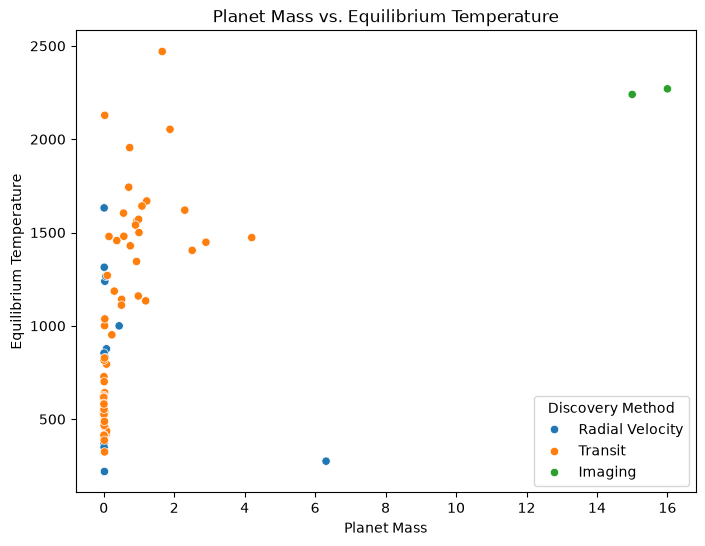

In [25]:
import seaborn as sns
plt.figure(figsize = (8,6))
sns.scatterplot(data=df, x="pl_bmassj", y="pl_eqt", hue="discoverymethod")
plt.title("Planet Mass vs. Equilibrium Temperature")
plt.xlabel("Planet Mass")
plt.ylabel("Equilibrium Temperature")
plt.legend(title = "Discovery Method")
plt.show()

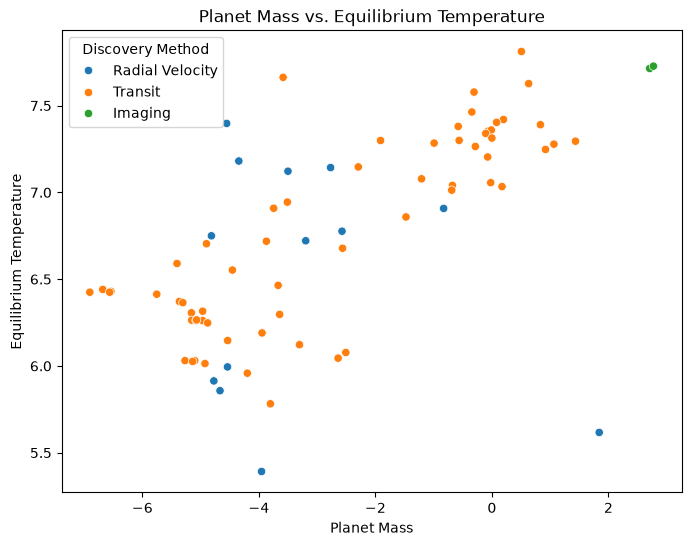

In [36]:
import seaborn as sns
plt.figure(figsize = (8,6))
sns.scatterplot(data=df, x=np.log(df["pl_bmassj"]), y=np.log(df["pl_eqt"]), hue="discoverymethod")
plt.title("Planet Mass vs. Equilibrium Temperature")
plt.xlabel("Planet Mass")
plt.ylabel("Equilibrium Temperature")
plt.legend(title = "Discovery Method")
plt.show()

In [37]:
# Exoplanets found by the imaging method are more likely to be massive 

In [38]:
mass_bigger_than_5 = df[df["pl_bmassj"] > 5]
print(mass_bigger_than_5["pl_eqt"].idxmin())

597


In [39]:
df.loc[597]

pl_name                eps Ind A b
hostname                 eps Ind A
discoverymethod    Radial Velocity
st_spectype                   K5 V
pl_eqt                       275.0
pl_bmassj                     6.31
Name: 597, dtype: object

In [40]:
# Name: eps Ind A b
# Index: 597
# Equilibrium Temperature: 275.0 K
# Mass: 6.31 Jupiter masses 
# It's orbiting a K5 V star which is somewhat similar to the sun

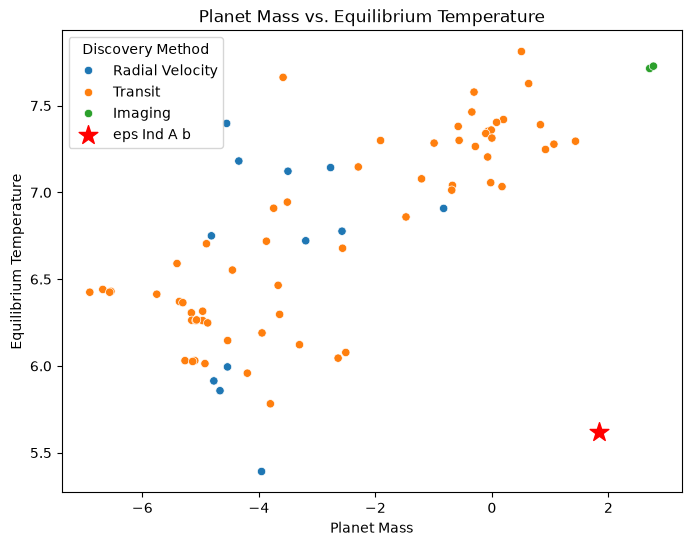

In [54]:
import seaborn as sns
plt.figure(figsize = (8,6))
sns.scatterplot(data = df, x=np.log(df["pl_bmassj"]), y=np.log(df["pl_eqt"]), hue="discoverymethod")
plt.title("Planet Mass vs. Equilibrium Temperature")
plt.xlabel("Planet Mass")
plt.ylabel("Equilibrium Temperature")

star = df[df["pl_name"] == "eps Ind A b"]

plt.scatter(x=np.log(star["pl_bmassj"]),y=np.log(star["pl_eqt"]), color = "red", marker="*", s=200, label = star["pl_name"].values[0])

plt.legend(title = "Discovery Method")
plt.show()

In [51]:
star

,pl_name,hostname,discoverymethod,st_spectype,pl_eqt,pl_bmassj
597,eps Ind A b,eps Ind A,Radial Velocity,K5 V,275.0,6.31


In [ ]:
# The title of the paper is "A temperate super-Jupiter imaged with JWST in the mid-infrared"
# The James Webb Space Telescope imaged a massive (about 6 times the mass of Jupiter) and cold exoplanet. It's name is Eps Ind A b and it's orbiting a K5V star. Data indicates that it's the only giant planet in the system. 
# Yes, my answer matches the exoplanet!
# It's special because it's massive and the coldest exoplanet humans have ever directly imaged. 
# Yes, the mass and equilibrium temperature match what the paper reported. 